# 実験2 (ex002): モーメンタム係数 $\mu$ の感度解析 (Table II) と収束曲線比較 (Fig. 3) の再現実験

本ノートブックでは，Ninomiya (NOLTA, IEICE 2017) の **4.1節 Example 1** における以下の2つの詳細検証を再現する．

1. **モーメンタム係数 $\mu$ の影響評価（論文 Table II の再現）**:
   - $\mu \in \{0.05, 0.10, 0.15, \dots, 0.95\}$（全19段階）について，それぞれ30回の独立試行（計 $19 \times 30 = 570$ 試行）を **NAQ (Armijo)** および **NAG (Armijo)** で実行し，$\mu$ が収束速度（平均エポック数・計算時間）および解の品質（平均・最良・最悪誤差）に与える影響を定量評価する．
2. **早期終了条件なしでの平均訓練誤差収束曲線の比較（論文 Fig. 3 の再現）**:
   - 勾配ノルムによる終了判定を無効化し，$k = 100,000$ エポックまで **QN** および **NAQ ($\mu = 0.80, 0.85, 0.90, 0.95$)** を30試行ずつ学習させ，反復回数に対する平均訓練誤差 $E_{\mathrm{train}}(\mathbf{w})$ の減衰特性を比較する．

In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import (
    setup_japanese_matplotlib,
    load_ex1_dataset,
    generate_initial_weights,
    run_mu_sweep_batched,
    run_convergence_curves_no_stop,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'})")

ds = load_ex1_dataset(dataset_dir="../datasets", seed=2017, device=device)
X_train, XT_train, D_train = ds["X_train"], ds["XT_train"], ds["D_train"]
X_test, D_test = ds["X_test"], ds["D_test"]

# ex001 と同一の30試行初期重みセット
w_init_30 = generate_initial_weights(num_runs=30, num_params=22, seed=2017, device=device)

使用デバイス: cuda (NVIDIA GeForce RTX 4080)


## 1. モーメンタム係数 $\mu \in [0.05, 0.95]$ の感度解析（論文 Table II）

全19通りの $\mu$ と30試行を掛け合わせた $570$ 個のネットワークを単一バッチテンソルとしてGPU上で一括並列学習する．

In [2]:
mu_values = [round(0.05 * i, 2) for i in range(1, 20)]  # 0.05, 0.10, ..., 0.95

naq_sweep = run_mu_sweep_batched(
    algo="NAQ",
    mu_list=mu_values,
    w_init_single_set=w_init_30,
    X_train=X_train,
    XT_train=XT_train,
    D_train=D_train,
    X_test=X_test,
    D_test=D_test,
    eps=1e-6,
    max_epochs=100000,
    max_step_norm=1.0,
)

nag_sweep = run_mu_sweep_batched(
    algo="NAG",
    mu_list=mu_values,
    w_init_single_set=w_init_30,
    X_train=X_train,
    XT_train=XT_train,
    D_train=D_train,
    X_test=X_test,
    D_test=D_test,
    eps=1e-6,
    max_epochs=100000,
    max_step_norm=1.0,
)

table2_rows = []
for r_naq, r_nag in zip(naq_sweep, nag_sweep):
    table2_rows.append({
        "mu": f"{r_naq['mu']:.2f}",
        "NAQ E_train (Ave/Best/Worst)": f"{r_naq['train_ave']:.3f} / {r_naq['train_best']:.3f} / {r_naq['train_worst']:.3f}",
        "NAQ Ave. T(sec)": round(r_naq["est_time_sec"], 4),
        "NAQ Ave. epochs": int(round(r_naq["ave_epochs"])),
        "NAG E_train (Ave/Best/Worst)": f"{r_nag['train_ave']:.3f} / {r_nag['train_best']:.3f} / {r_nag['train_worst']:.3f}",
        "NAG Ave. T(sec)": round(r_nag["est_time_sec"], 4),
        "NAG Ave. epochs": int(round(r_nag["ave_epochs"])),
    })

df_table2 = pd.DataFrame(table2_rows)
df_table2.to_csv("../datasets/ex002_table2_mu_effect.csv", index=False, encoding="utf-8-sig")
df_table2

NAG mu-sweep (19x30=570 runs): 100%|##########| 100000/100000 [08:53<00:00, 187.34it/s, E_ave=44.789, active=570]


,mu,NAQ E_train (Ave/Best/Worst),NAQ Ave. T(sec),NAQ Ave. epochs,NAG E_train (Ave/Best/Worst),NAG Ave. T(sec),NAG Ave. epochs
0,0.05,11.134 / 0.227 / 47.948,1.3925,35900,54.015 / 52.447 / 55.620,0.9365,100000
1,0.10,10.669 / 0.999 / 37.157,1.2054,31075,53.974 / 51.401 / 55.608,0.9365,100000
2,0.15,9.892 / 0.770 / 27.086,0.5508,14200,53.890 / 50.921 / 56.048,0.9365,100000
3,0.20,8.924 / 0.678 / 29.375,0.6048,15592,53.776 / 50.247 / 55.505,0.9365,100000
4,0.25,7.264 / 0.223 / 22.249,0.6087,15692,53.578 / 49.195 / 55.420,0.9365,100000
5,0.30,6.993 / 0.186 / 14.910,0.4661,12017,53.629 / 48.674 / 55.314,0.9365,100000
6,0.35,9.403 / 0.187 / 37.841,0.3142,8100,53.625 / 46.582 / 55.494,0.9365,100000
7,0.40,6.703 / 0.495 / 24.633,0.2098,5408,53.432 / 45.718 / 54.969,0.9365,100000
8,0.45,9.135 / 0.189 / 28.850,0.2864,7383,52.927 / 36.544 / 54.638,0.9365,100000
9,0.50,8.173 / 0.299 / 20.278,0.1726,4450,52.237 / 33.822 / 54.227,0.9365,100000


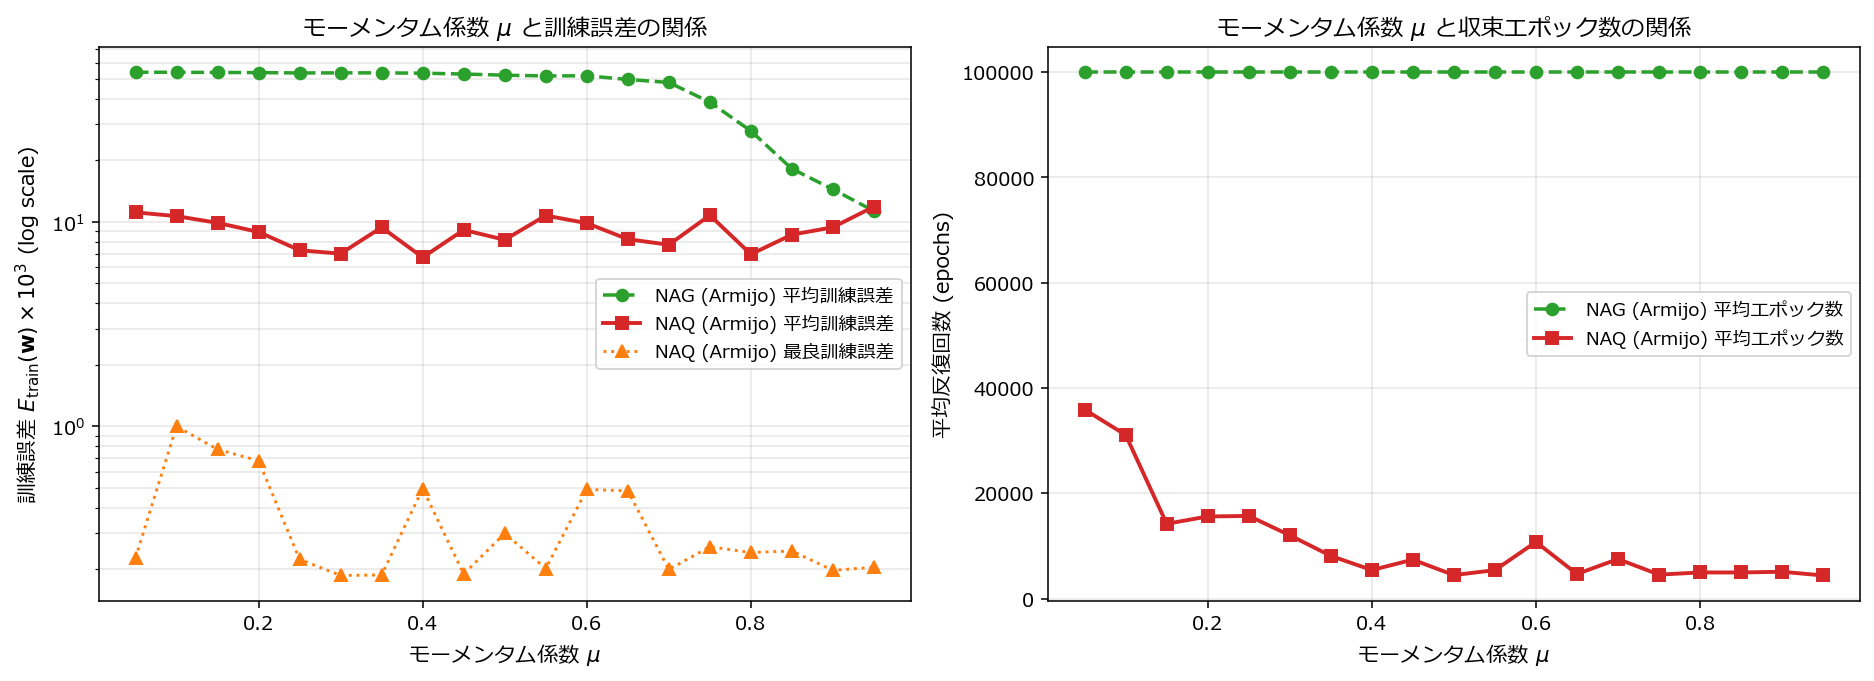

In [3]:
# Table II の可視化: mu に対する平均訓練誤差と平均収束エポック数の推移
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

mu_arr = np.array(mu_values)
naq_err_ave = np.array([r["train_ave"] for r in naq_sweep])
naq_err_best = np.array([r["train_best"] for r in naq_sweep])
nag_err_ave = np.array([r["train_ave"] for r in nag_sweep])

naq_ep = np.array([r["ave_epochs"] for r in naq_sweep])
nag_ep = np.array([r["ave_epochs"] for r in nag_sweep])

axes[0].plot(mu_arr, nag_err_ave, "o--", color="#2ca02c", lw=1.8, label="NAG (Armijo) 平均訓練誤差")
axes[0].plot(mu_arr, naq_err_ave, "s-", color="#d62728", lw=2.0, label="NAQ (Armijo) 平均訓練誤差")
axes[0].plot(mu_arr, naq_err_best, "^:", color="#ff7f0e", lw=1.5, label="NAQ (Armijo) 最良訓練誤差")
axes[0].set_yscale("log")
axes[0].set_xlabel("モーメンタム係数 $\mu$", fontsize=11)
axes[0].set_ylabel("訓練誤差 $E_{\mathrm{train}}(\mathbf{w}) \times 10^3$ (log scale)", fontsize=11)
axes[0].set_title("モーメンタム係数 $\mu$ と訓練誤差の関係", fontsize=12)
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=9.5)

axes[1].plot(mu_arr, nag_ep, "o--", color="#2ca02c", lw=1.8, label="NAG (Armijo) 平均エポック数")
axes[1].plot(mu_arr, naq_ep, "s-", color="#d62728", lw=2.0, label="NAQ (Armijo) 平均エポック数")
axes[1].set_xlabel("モーメンタム係数 $\mu$", fontsize=11)
axes[1].set_ylabel("平均反復回数 (epochs)", fontsize=11)
axes[1].set_title("モーメンタム係数 $\mu$ と収束エポック数の関係", fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
plt.savefig("../report/img/ex002_mu_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. 終了条件なし 100,000 エポック学習における収束曲線の比較（論文 Fig. 3）

論文 Fig. 3 と同様に，QN ($\mu = 0$) および NAQ ($\mu = 0.80, 0.85, 0.90, 0.95$) について早期終了判定を行わずに $100,000$ エポックまで学習させ，30試行の平均訓練誤差 $E_{\mathrm{train}}(\mathbf{w})$ の推移を比較する．

Fig.3 Convergence (5x30=150 runs, no early-stop): 100%|##########| 100000/100000 [03:54<00:00, 425.96it/s]


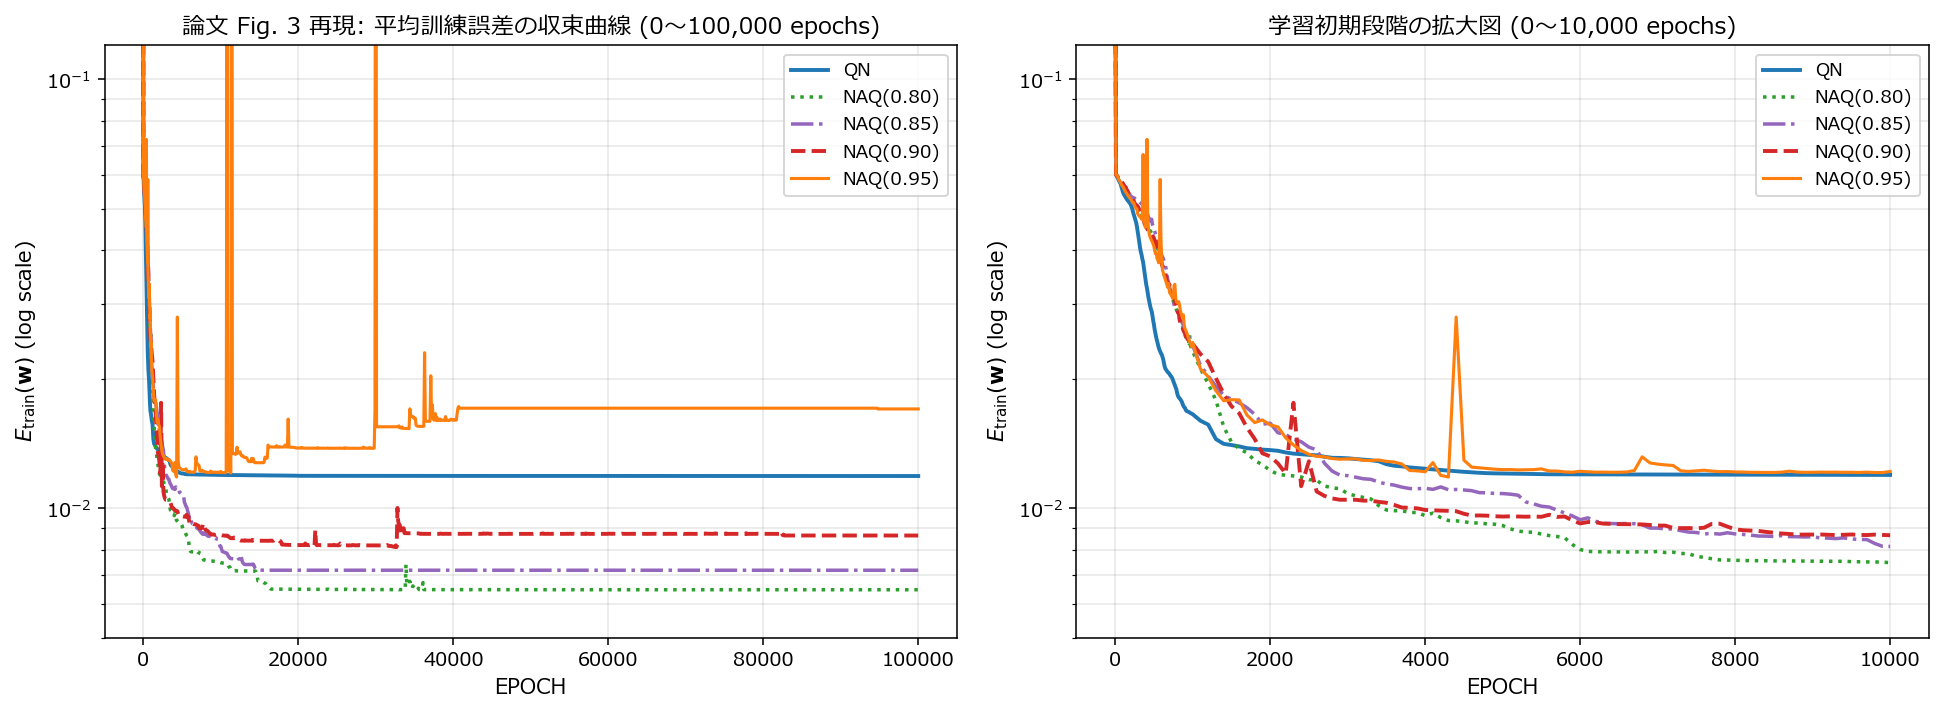

,Epoch (x10^3 error shown),QN,NAQ(0.80),NAQ(0.85),NAQ(0.90),NAQ(0.95)
0,0,221.7728,221.7728,221.7728,221.7728,221.7728
50,500,26.8133,42.3371,44.7682,42.6213,40.7718
110,2000,13.6788,12.2585,15.8001,13.2244,15.6517
140,5000,12.0640,9.1204,10.8308,9.5736,12.3148
190,10000,11.9695,7.4777,8.1543,8.6607,12.1937
290,20000,11.9143,6.4822,7.1785,8.2161,13.8310
590,50000,11.9052,6.4648,7.1776,8.7243,17.1260
1090,100000,11.9002,6.4648,7.1776,8.6474,17.0555


In [4]:
fig3_mus = [0.0, 0.80, 0.85, 0.90, 0.95]
conv_data = run_convergence_curves_no_stop(
    mu_configs=fig3_mus,
    w_init_single_set=w_init_30,
    X_train=X_train,
    XT_train=XT_train,
    D_train=D_train,
    max_epochs=100000,
    record_stride=100,
    max_step_norm=1.0,
)

df_conv = pd.DataFrame(conv_data)
df_conv.to_csv("../datasets/ex002_fig3_convergence.csv", index=False)

# 論文 Fig. 3 再現プロット (全体 0〜100,000 epoch + 初期 0〜15,000 epoch 拡大図)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
styles = [
    ("QN",        "#1f77b4", "-",  2.0),
    ("NAQ(0.80)", "#2ca02c", ":",  1.8),
    ("NAQ(0.85)", "#9467bd", "-.", 1.8),
    ("NAQ(0.90)", "#d62728", "--", 2.0),
    ("NAQ(0.95)", "#ff7f0e", "-",  1.6),
]

ep_x = conv_data["epochs"]
for key, col, ls, lw in styles:
    axes[0].plot(ep_x, conv_data[key], label=key, color=col, linestyle=ls, lw=lw)
    mask_early = ep_x <= 15000
    axes[1].plot(ep_x[mask_early], conv_data[key][mask_early], label=key, color=col, linestyle=ls, lw=lw)

for ax, title_str in [
    (axes[0], "論文 Fig. 3 再現: 平均訓練誤差の収束曲線 (0〜100,000 epochs)"),
    (axes[1], "学習初期段階の拡大図 (0〜15,000 epochs)"),
]:
    ax.set_yscale("log")
    ax.set_xlabel("EPOCH", fontsize=11)
    ax.set_ylabel("$E_{\mathrm{train}}(\mathbf{w})$ (log scale)", fontsize=11)
    ax.set_title(title_str, fontsize=12)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=9.5)

plt.tight_layout()
plt.savefig("../report/img/ex002_convergence_curves.png", dpi=160, bbox_inches="tight")
plt.show()

# 最終エポック (k=100,000) および k=2,000, 5,000, 10,000 時点での平均訓練誤差 (x10^3) の確認表
check_pts = [0, 500, 2000, 5000, 10000, 20000, 50000, 100000]
df_pts = df_conv[df_conv["epochs"].isin(check_pts)].copy()
for c in ["QN", "NAQ(0.80)", "NAQ(0.85)", "NAQ(0.90)", "NAQ(0.95)"]:
    df_pts[c] = (df_pts[c] * 1000.0).round(4)
df_pts.rename(columns={"epochs": "Epoch (x10^3 error shown)"})